# F1 - Flood mapping with Sentinel-1 (radar) and Sentinel-2 (optical): the complete notebook

This one file replaces the four session notebooks. Every code line has a remark beside it.

| Part | What it does | Time |
|---|---|---|
| 0 | Install tools, check the GPU, download the data if missing | 2-5 min |
| 1 | Settings (the only place you change things) | - |
| 2 | Helper routines and the train / valid / test lists | seconds |
| 3 | Look at the data: counts, one chip in every layer, totals | 2-3 min |
| 4 | Simple-rule baselines: NDWI (optical) and VH (radar) | 5-10 min |
| 5 | The U-Net: preparing inputs, batches, loss, scoring, training routine | seconds |
| 6 | Train: one mode at a time, or all three modes in one go | 6 min per run |
| 7 | Summary table: mean, lowest and highest test IoU per mode | seconds |

**Run the parts in order the first time.** Before running: **Runtime -> Change runtime type -> T4 GPU**.

**Fairness rules built in:** cut-offs and the best epoch are chosen on train / valid chips only; the test chips are scored once per run; every method is scored on the same usable pixels.

## Part 0 - setup

In [1]:
!pip -q install segmentation-models-pytorch rasterio    # smp = ready-made U-Net; rasterio = reads GeoTIFF files

In [2]:
import glob, os, csv, collections, random, time, gc, subprocess, statistics as st   # standard tools (gc = free memory, st = statistics)
import numpy as np, rasterio                          # numpy = number tables, rasterio = reads GeoTIFF files
import matplotlib.pyplot as plt                       # matplotlib = draws pictures
import torch, torch.nn.functional as F                # PyTorch = the deep-learning engine
import segmentation_models_pytorch as smp             # smp = gives us a U-Net in one line

DATA = "data"                                         # folder that holds all the downloaded files

device = "cuda" if torch.cuda.is_available() else "cpu"     # use the GPU if there is one
print("running on:", device)                                # you want to see: cuda
if device == "cpu":                                         # no GPU?
    print("WARNING: no GPU found. Training would be very slow. Runtime -> Change runtime type -> T4 GPU")

running on: cuda


In [3]:
if not os.path.isdir(f"{DATA}/S1Hand"):               # only download if the data is not already here
    script = '''
mkdir -p data/S1Hand data/S2Hand data/LabelHand data/splits
B=gs://sen1floods11/v1.1
gsutil -m -q cp -r $B/data/flood_events/HandLabeled/S1Hand/*    data/S1Hand/
gsutil -m -q cp -r $B/data/flood_events/HandLabeled/S2Hand/*    data/S2Hand/
gsutil -m -q cp -r $B/data/flood_events/HandLabeled/LabelHand/* data/LabelHand/
gsutil -m -q cp -r $B/splits/flood_handlabeled/*                data/splits/
'''                                                   # the same copy commands as Session 1
    subprocess.run(["bash", "-c", script], check=True)    # run them
for folder in ["S1Hand", "S2Hand", "LabelHand"]:      # count the files in each folder
    print(folder, len(os.listdir(f"{DATA}/{folder}")), "files")   # expect 446 each
print("splits:", sorted(os.listdir(f"{DATA}/splits")))              # the list files

S1Hand 446 files
S2Hand 446 files
LabelHand 446 files
splits: ['flood_bolivia_data.csv', 'flood_test_data.csv', 'flood_train_data.csv', 'flood_valid_data.csv']


## Part 1 - settings
This is the only cell you edit. `MODE` and `SEEDS` are the two you will change most.

In [4]:
MODE = "s2"                 # inputs: "s2" = optical only, "s1" = radar only, "both" = stacked together
SEEDS = [0, 1, 2]           # one full training run per seed in this list
RUN_ALL = False             # True = run only Part 6C (skip 6A, 6B): trains all three modes, about 50 minutes
ENCODER = "resnet34"        # the part of the U-Net that reads the picture
ENCODER_WEIGHTS = "imagenet"   # start from a network already trained on ordinary photos (None = from zero)
EPOCHS = 30                 # how many full passes through the training chips
BATCH = 8                   # chips shown to the model at one time
CROP = 256                  # during training, cut random 256 x 256 squares out of each chip
LR = 1e-3                   # learning rate: how big each correction step is

BASELINE_NDWI_TEST = float("nan")   # filled in automatically by Part 4
BASELINE_VH_TEST = float("nan")     # filled in automatically by Part 4

## Part 2 - helper routines and the train / valid / test lists

In [5]:
def load(chip):                                                           # give a chip ID, get 3 things back
    with rasterio.open(f"{DATA}/S1Hand/{chip}_S1Hand.tif") as s:         # open the radar file
        s1 = s.read().astype("float32")                                   # read VV and VH as decimal numbers
    with rasterio.open(f"{DATA}/S2Hand/{chip}_S2Hand.tif") as s:         # open the optical file
        s2 = s.read().astype("float32")                                   # read the 13 optical layers
    with rasterio.open(f"{DATA}/LabelHand/{chip}_LabelHand.tif") as s:   # open the answer file
        lab = s.read(1)                                                   # read the answer layer
    return s1, s2, lab                                                    # hand back radar, optical, answer

def read_split(filename):                                  # read one list file and return its chip IDs
    ids = []                                               # empty list for the IDs
    with open(f"{DATA}/splits/{filename}") as f:           # open the list file
        for row in csv.reader(f):                          # go through it line by line
            if not row:                                    # skip empty lines
                continue
            if "_S1Hand" in row[0]:                        # only real entries
                ids.append(os.path.basename(row[0]).replace("_S1Hand.tif", ""))   # keep the chip ID
    return ids                                             # hand back the IDs

def usable_pixels(s1, s2, lab):                    # True where a pixel can be fairly judged
    ok = lab != -1                                 # a person checked this pixel
    ok = ok & ~np.isnan(s1).any(axis=0)            # and the radar has a reading
    ok = ok & (s2 != 0).any(axis=0)                # and the optical is not an empty pixel
    return ok                                      # the map of usable pixels

chips = []                                                      # all chip IDs
for path in sorted(glob.glob(f"{DATA}/S1Hand/*_S1Hand.tif")):   # every radar file, in order
    chips.append(os.path.basename(path).replace("_S1Hand.tif", ""))   # keep the chip ID only

train_ids = read_split("flood_train_data.csv")     # chips for training
valid_ids = read_split("flood_valid_data.csv")     # chips for choosing cut-offs and the best epoch
test_ids = read_split("flood_test_data.csv")       # chips kept for the final honest score
print("all chips:", len(chips), "| train / valid / test:", len(train_ids), len(valid_ids), len(test_ids))   # 446 | 252 89 90

all chips: 446 | train / valid / test: 252 89 90


## Part 3 - look at the data (was Session 1)

In [6]:
events = []                                                     # empty list for the event names
for c in chips:                                                 # go through every chip ID
    events.append(c.split("_")[0])                              # first word before "_" = flood event name
print("chips per event:", dict(collections.Counter(events)))    # tally per event
for name, ids in [("train", train_ids), ("valid", valid_ids), ("test", test_ids)]:   # for each list ...
    print(name, dict(collections.Counter(i.split("_")[0] for i in ids)))           # ... chips per event

chips per event: {'Bolivia': 15, 'Ghana': 53, 'India': 68, 'Mekong': 30, 'Nigeria': 18, 'Pakistan': 28, 'Paraguay': 67, 'Somalia': 26, 'Spain': 30, 'Sri-Lanka': 42, 'USA': 69}
train {'Ghana': 31, 'India': 40, 'Mekong': 18, 'Nigeria': 10, 'Pakistan': 16, 'Paraguay': 39, 'Somalia': 15, 'Spain': 18, 'Sri-Lanka': 24, 'USA': 41}
valid {'Ghana': 11, 'India': 14, 'Mekong': 6, 'Nigeria': 4, 'Pakistan': 6, 'Paraguay': 14, 'Somalia': 5, 'Spain': 6, 'Sri-Lanka': 9, 'USA': 14}
test {'Ghana': 11, 'India': 14, 'Mekong': 6, 'Nigeria': 4, 'Pakistan': 6, 'Paraguay': 14, 'Somalia': 6, 'Spain': 6, 'Sri-Lanka': 9, 'USA': 14}


In [7]:
chip = chips[0]                                                           # take the first chip (computers count from 0)
s1, s2, lab = load(chip)                                                  # fetch its three files
print(chip)                                                               # which chip we opened
print("S1", s1.shape,                                                     # radar table size: (layers, rows, columns)
      "| NaNs:", int(np.isnan(s1).sum()),                                 # count blank cells (NaN = no reading)
      "| VV range (dB):", np.nanmin(s1[0]), np.nanmax(s1[0]))             # smallest and largest VV value, ignoring blanks
print("S2", s2.shape, "| value range:", s2.min(), s2.max())               # optical table size and value range
print("label values (-1 nodata, 0 not water, 1 water):",                  # which answer values exist ...
      dict(zip(*np.unique(lab, return_counts=True))))                     # ... and how many pixels have each

Bolivia_103757
S1 (2, 512, 512) | NaNs: 321042 | VV range (dB): -40.82144 -0.69059896
S2 (13, 512, 512) | value range: 0.0 5662.0
label values (-1 nodata, 0 not water, 1 water): {np.int16(-1): np.int64(174067), np.int16(0): np.int64(52715), np.int16(1): np.int64(35362)}


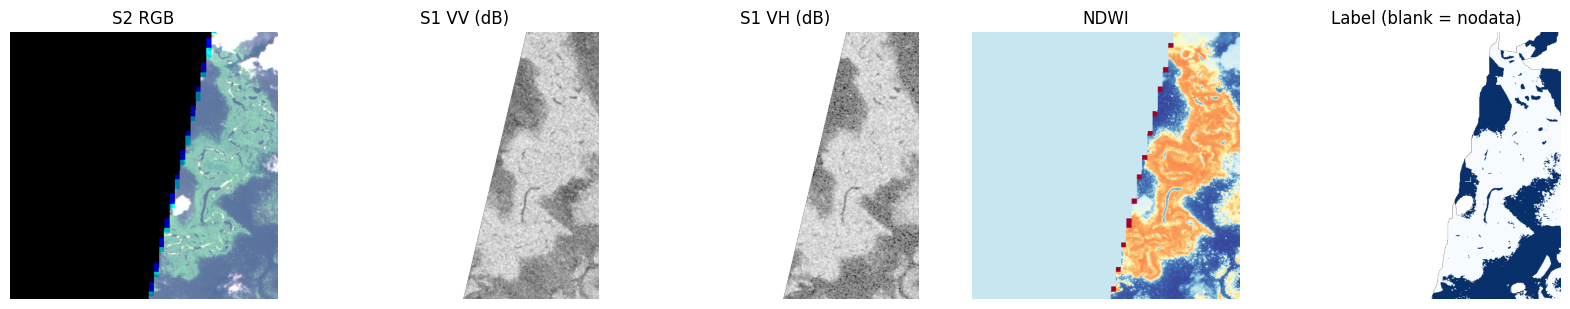

In [8]:
def stretch(x, lo=2, hi=98):                          # make a picture easier to see: spread the brightness
    a, b = np.nanpercentile(x, [lo, hi])              # find the 2% and 98% brightness points (ignore extreme outliers)
    return np.clip((x - a) / (b - a + 1e-9), 0, 1)    # rescale so those points become 0 and 1

# Optical layer order is B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B10,B11,B12. Counting starts from 0.
rgb = np.dstack([stretch(s2[3]), stretch(s2[2]), stretch(s2[1])])   # stack Red(B4), Green(B3), Blue(B2) = natural colour photo
ndwi = (s2[2] - s2[7]) / (s2[2] + s2[7] + 1e-9)                     # water index (Green - NIR) / (Green + NIR), as in your notes
lab_m = np.ma.masked_where(lab == -1, lab)                          # hide the "no data" pixels so they stay blank

fig, ax = plt.subplots(1, 5, figsize=(20, 4))                       # prepare a row of 5 empty picture boxes
panels = [(rgb, "S2 RGB", None),                                    # panel 1: natural colour photo
          (s1[0], "S1 VV (dB)", "gray"),                            # panel 2: radar VV in grey (water = dark)
          (s1[1], "S1 VH (dB)", "gray"),                            # panel 3: radar VH in grey
          (ndwi, "NDWI", "RdYlBu"),                                 # panel 4: water index (blue = water)
          (lab_m, "Label (blank = nodata)", "Blues")]               # panel 5: the checked answer (dark blue = water)
for a, (img, title, cmap) in zip(ax, panels):                       # fill each box with its picture
    a.imshow(img, cmap=cmap)                                        # draw the picture
    a.set_title(title)                                              # write its title above it
    a.axis("off")                                                   # hide the axis numbers
plt.show()                                                          # show the finished row of pictures

In [9]:
water = 0                                    # running count of water pixels
valid = 0                                    # running count of pixels that have an answer
nan_chips = 0                                # running count of chips with blank radar readings

for c in chips:                              # go through all 446 chips one by one
    s1, s2, lab = load(c)                    # open this chip's three files
    if np.isnan(s1).any():                   # does this chip have any blank radar readings?
        nan_chips = nan_chips + 1            # yes -> add 1 to the count
    has_answer = lab != -1                   # True where the pixel was actually checked by people
    valid = valid + int(has_answer.sum())    # add this chip's checked pixels to the total
    water = water + int((lab == 1).sum())    # add this chip's water pixels to the total

print(f"water share of valid pixels: {100 * water / valid:.1f}%")   # water pixels as a percent of checked pixels
print("chips with NaNs in S1:", nan_chips, "of", len(chips))        # how many chips have blank radar readings

water share of valid pixels: 10.6%
chips with NaNs in S1: 46 of 446


## Part 4 - simple-rule baselines (was Session 2)
A simple rule with no learning. Any model must beat these. Cut-offs are chosen on **train** only.

In [10]:
def iou(tp, fp, fn):                               # the score from three counts
    total = tp + fp + fn                           # all pixels that are water in the rule OR in the answer
    if total == 0:                                 # nothing to score
        return float("nan")
    return tp / total                              # overlap / combined area

def sweep(ids, make_index, thresholds, water_is_high):       # try many cut-offs in one pass over the chips
    counts = {t: [0, 0, 0] for t in thresholds}               # for each cut-off: [hits, false alarms, misses]
    for c in ids:                                             # go through the chips one by one
        s1, s2, lab = load(c)                                 # open this chip
        ok = usable_pixels(s1, s2, lab)                       # which pixels can be judged
        truth = lab == 1                                      # where the answer says water
        index = make_index(s1, s2)                            # compute the value the rule looks at
        for t in thresholds:                                  # try each cut-off value
            pred = index > t if water_is_high else index < t  # rule says water (above or below the cut-off)
            counts[t][0] += int((pred & truth & ok).sum())    # hit: rule says water, answer says water
            counts[t][1] += int((pred & ~truth & ok).sum())   # false alarm: rule says water, answer says not
            counts[t][2] += int((~pred & truth & ok).sum())   # miss: rule says not water, answer says water
    return counts                                             # all counts, one entry per cut-off

In [11]:
def ndwi_index(s1, s2):                              # the value the optical rule looks at
    green, nir = s2[2], s2[7]                       # optical layers B3 (green) and B8 (NIR), counting from 0
    return (green - nir) / (green + nir + 1e-9)     # water index; tiny number avoids dividing by zero

ndwi_cutoffs = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4]          # cut-off values to try
ndwi_train = sweep(train_ids, ndwi_index, ndwi_cutoffs, True)       # score each cut-off on the train chips (water = high)

print("NDWI cut-off | train IoU")                                    # table heading
for t in ndwi_cutoffs:                                               # one line per cut-off
    print(f"{t:>12} | {iou(*ndwi_train[t]):.3f}")                    # show its score
best_ndwi = max(ndwi_cutoffs, key=lambda t: iou(*ndwi_train[t]))     # the cut-off with the best train score
print("best NDWI cut-off (chosen on train):", best_ndwi)             # report it
if best_ndwi in (ndwi_cutoffs[0], ndwi_cutoffs[-1]):                 # is the best value at the edge of our list?
    print("WARNING: best cut-off is at the edge of the list - widen the list and run again")   # a better one may lie outside

NDWI cut-off | train IoU
        -0.3 | 0.240
        -0.2 | 0.420
        -0.1 | 0.649
         0.0 | 0.651
         0.1 | 0.491
         0.2 | 0.317
         0.3 | 0.214
         0.4 | 0.075
best NDWI cut-off (chosen on train): 0.0


In [12]:
def vh_index(s1, s2):                                 # the value the radar rule looks at
    return s1[1]                                      # radar layer 1 = VH (layer 0 = VV)

vh_cutoffs = [-28, -26, -24, -22, -20, -18, -16, -14, -12]           # cut-off values to try, in dB
vh_train = sweep(train_ids, vh_index, vh_cutoffs, False)             # score each cut-off on the train chips (water = low)

print("VH cut-off (dB) | train IoU")                                 # table heading
for t in vh_cutoffs:                                                 # one line per cut-off
    print(f"{t:>15} | {iou(*vh_train[t]):.3f}")                      # show its score
best_vh = max(vh_cutoffs, key=lambda t: iou(*vh_train[t]))           # the cut-off with the best train score
print("best VH cut-off (chosen on train):", best_vh)                 # report it
if best_vh in (vh_cutoffs[0], vh_cutoffs[-1]):                       # is the best value at the edge of our list?
    print("WARNING: best cut-off is at the edge of the list - widen the list and run again")   # a better one may lie outside

VH cut-off (dB) | train IoU
            -28 | 0.324
            -26 | 0.416
            -24 | 0.464
            -22 | 0.439
            -20 | 0.349
            -18 | 0.241
            -16 | 0.160
            -14 | 0.117
            -12 | 0.101
best VH cut-off (chosen on train): -24


In [13]:
rows = []                                                              # empty list for the table lines
for name, fn, t, high in [("NDWI (optical)", ndwi_index, best_ndwi, True),    # the two rules with their chosen cut-offs
                          ("VH (radar)", vh_index, best_vh, False)]:
    line = [name, t]                                                   # start the line: rule name and cut-off
    for ids in [train_ids, valid_ids, test_ids]:                       # score on train, valid and test
        counts = sweep(ids, fn, [t], high)[t]                          # run the rule with the chosen cut-off
        line.append(round(iou(*counts), 3))                            # add its IoU score
    rows.append(line)                                                  # add the finished line to the table

print(f"{'rule':<16}{'cut-off':>9}{'train':>9}{'valid':>9}{'test':>9}")   # table heading
for r in rows:                                                         # print each line
    print(f"{r[0]:<16}{r[1]:>9}{r[2]:>9}{r[3]:>9}{r[4]:>9}")

BASELINE_NDWI_TEST = rows[0][4]    # TEST IoU of the optical rule, taken from the table above
BASELINE_VH_TEST = rows[1][4]      # TEST IoU of the radar rule, taken from the table above
print("saved for later:", BASELINE_NDWI_TEST, BASELINE_VH_TEST)

rule              cut-off    train    valid     test
NDWI (optical)        0.0    0.651    0.672    0.772
VH (radar)            -24    0.464    0.488    0.523
saved for later: 0.772 0.523


In [14]:
nan_total = 0                                         # all blank-radar pixels
nan_and_unmarked = 0                                  # blank-radar pixels that also have no answer
for c in chips:                                       # go through all chips
    s1, s2, lab = load(c)                             # open the chip
    blank = np.isnan(s1).any(axis=0)                  # True where radar has no reading
    nan_total += int(blank.sum())                     # add to the total
    nan_and_unmarked += int((blank & (lab == -1)).sum())   # add those that are also unmarked
if nan_total > 0:                                     # avoid dividing by zero
    print(f"{100 * nan_and_unmarked / nan_total:.1f}% of blank-radar pixels are also unmarked in the answer")
else:
    print("no blank radar pixels found")

93.6% of blank-radar pixels are also unmarked in the answer


## Part 5 - the U-Net: inputs, batches, loss, scoring, training routine (was Session 3)
Running these cells only **defines** routines. Training happens in Part 6.

In [15]:
def prepare(s1, s2, mode):                                     # turn raw chip data into the network's input
    layers = []                                                # list of layer groups to stack
    if mode in ("s2", "both"):                                 # optical wanted?
        layers.append(np.clip(s2 / 10000.0, 0, 1))             # optical: divide by 10000 -> reflectance, limit to 0..1
    if mode in ("s1", "both"):                                 # radar wanted?
        r = np.clip(s1, -30, 0)                                # radar: limit to -30..0 dB
        r = (r + 30) / 30                                      # rescale to 0..1
        r = np.nan_to_num(r, nan=0.5)                          # blank readings -> neutral middle value
        layers.append(r)
    return np.concatenate(layers, axis=0).astype("float16")    # stack all layers; float16 saves memory

def build_set(ids):                                            # load a whole list of chips into memory
    X, Y, OK = [], [], []                                      # inputs, answers, usable-pixel maps
    for c in ids:                                              # go through each chip
        s1, s2, lab = load(c)                                  # open it
        ok = usable_pixels(s1, s2, lab)                        # which pixels count
        X.append(torch.from_numpy(prepare(s1, s2, MODE)))      # the network's input
        Y.append(torch.from_numpy((lab == 1).astype("float16")))   # answer: 1 = water, 0 = not water
        OK.append(torch.from_numpy(ok.astype("float16")))      # 1 = this pixel counts, 0 = ignore it
    return X, Y, OK

In [16]:
def get_batch(X, Y, OK, idx, crop, train):                     # assemble a few chips into one batch
    xs, ys, oks = [], [], []                                   # empty lists
    for i in idx:                                              # for each chip chosen
        x, y, ok = X[i], Y[i], OK[i]                           # its input, answer, usable map
        if train:                                              # training: add variety
            size = x.shape[-1]                                 # chip width in pixels (512)
            top = random.randint(0, size - crop)               # random top edge of the square
            left = random.randint(0, size - crop)              # random left edge of the square
            x = x[:, top:top + crop, left:left + crop]         # cut the square out of the input
            y = y[top:top + crop, left:left + crop]            # same square from the answer
            ok = ok[top:top + crop, left:left + crop]          # same square from the usable map
            if random.random() < 0.5:                          # half the time ...
                x, y, ok = x.flip(-1), y.flip(-1), ok.flip(-1) # ... mirror left-right
            if random.random() < 0.5:                          # half the time ...
                x, y, ok = x.flip(-2), y.flip(-2), ok.flip(-2) # ... mirror top-bottom
        xs.append(x); ys.append(y); oks.append(ok)             # add to the batch
    xb = torch.stack(xs).float().to(device)                    # stack inputs, move to GPU
    yb = torch.stack(ys).float().unsqueeze(1).to(device)       # stack answers (add a layer dimension)
    okb = torch.stack(oks).float().unsqueeze(1).to(device)     # stack usable maps
    return xb, yb, okb

def masked_loss(logits, target, ok):                           # the penalty score, counting only usable pixels
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")   # penalty per pixel for wrong answers
    bce = (bce * ok).sum() / ok.sum().clamp(min=1)             # average over usable pixels only
    p = torch.sigmoid(logits) * ok                             # predicted water chance, usable pixels only
    t = target * ok                                            # true water, usable pixels only
    dice = 1 - (2 * (p * t).sum() + 1) / (p.sum() + t.sum() + 1)   # penalty for poor overlap
    return bce + dice                                          # total penalty

@torch.no_grad()                                               # no learning happens inside this routine
def evaluate(model, X, Y, OK):                                 # IoU score over a whole list of chips
    model.eval()                                               # switch the model to scoring mode
    tp = fp = fn = 0.0                                         # hits, false alarms, misses
    for s in range(0, len(X), 4):                              # 4 chips at a time
        idx = list(range(s, min(s + 4, len(X))))               # which chips
        xb, yb, okb = get_batch(X, Y, OK, idx, None, False)    # assemble them (full chips, no cropping)
        pred = (torch.sigmoid(model(xb)) > 0.5).float()        # water if the model is more than 50% sure
        tp += float((pred * yb * okb).sum())                   # hit: said water, answer water
        fp += float((pred * (1 - yb) * okb).sum())             # false alarm: said water, answer not
        fn += float(((1 - pred) * yb * okb).sum())             # miss: said not water, answer water
    return tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")   # IoU, same formula as Session 2

In [17]:
def train_and_test(seed):                                      # one complete run: train, pick the best epoch, score on test
    random.seed(seed); np.random.seed(seed)                    # fix the random numbers for this seed ...
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)  # ... so the run starts from the same point every time
    model = smp.Unet(encoder_name=ENCODER, encoder_weights=ENCODER_WEIGHTS,
                     in_channels=n_ch, classes=1).to(device)   # build the U-Net: n_ch layers in, 1 water layer out
    opt = torch.optim.Adam(model.parameters(), lr=LR)          # the tool that makes the corrections
    best_iou, best_epoch = -1.0, 0                             # best valid score so far
    weights_file = f"best_{MODE}_seed{seed}.pt"                # file name for this run's best model
    t0 = time.time()                                           # start the stopwatch
    for epoch in range(1, EPOCHS + 1):                         # repeat for every epoch
        model.train()                                          # switch the model to learning mode
        order = list(range(len(Xtr)))                          # one number per training chip
        random.shuffle(order)                                  # shuffle the order each epoch
        total, n = 0.0, 0                                      # running penalty total and batch count
        for s in range(0, len(order), BATCH):                  # go through the chips a batch at a time
            xb, yb, okb = get_batch(Xtr, Ytr, OKtr, order[s:s + BATCH], CROP, True)   # next batch
            loss = masked_loss(model(xb), yb, okb)             # model guesses; measure the penalty
            opt.zero_grad()                                    # clear the previous correction
            loss.backward()                                    # work out which way to correct
            opt.step()                                         # apply the correction
            total += loss.item(); n += 1                       # keep the running totals
        v = evaluate(model, Xva, Yva, OKva)                    # score on the validation chips (no learning)
        mark = ""                                              # note to print if this is the best so far
        if v > best_iou:                                       # better than every earlier epoch?
            best_iou, best_epoch = v, epoch                    # remember it
            torch.save(model.state_dict(), weights_file)       # save these model settings to a file
            mark = "  <- best so far"
        print(f"seed {seed} | epoch {epoch:>2} | train loss {total / n:.3f} | valid IoU {v:.3f}{mark}")   # one line per epoch
    print("training time:", round((time.time() - t0) / 60, 1), "minutes")
    model.load_state_dict(torch.load(weights_file, map_location=device))   # bring back the best epoch's settings
    test_iou = evaluate(model, Xte, Yte, OKte)                 # score on the test chips, once per run
    print(f"mode={MODE} seed={seed} | best epoch {best_epoch} | valid IoU {best_iou:.3f} | TEST IoU {test_iou:.3f}")   # the result
    with open("results.csv", "a") as f:                        # add one line to the results file
        f.write(f"{MODE},{seed},{ENCODER},{ENCODER_WEIGHTS},{EPOCHS},{best_epoch},{best_iou:.4f},{test_iou:.4f}\n")
    return test_iou

## Part 6 - train
**6A** loads the data for the current `MODE`. **6B** trains once per seed. **6C** (optional) does all three modes in one go.
**Two ways to use it - pick one:**
- *One mode at a time:* set `MODE` in Part 1, run Part 1, then 6A and 6B; repeat with the next mode. Leave `RUN_ALL = False`.
- *Everything in one go:* set `RUN_ALL = True` in Part 1, run Part 1, then **skip 6A and 6B and run only 6C**.

In [18]:
t0 = time.time()                                               # start the stopwatch
Xtr, Ytr, OKtr = build_set(train_ids)                          # training chips
Xva, Yva, OKva = build_set(valid_ids)                          # validation chips
Xte, Yte, OKte = build_set(test_ids)                           # test chips
n_ch = Xtr[0].shape[0]                                         # how many input layers the network gets
print("MODE:", MODE, "| input layers:", n_ch, "| loaded in", round(time.time() - t0), "seconds")   # s2=13, s1=2, both=15
RUN_ALL = True                                              # True = run only Part 6C (skip 6A, 6B): trains all three modes, about 50 minutes

MODE: s2 | input layers: 13 | loaded in 26 seconds


In [19]:
#for seed in SEEDS:                 # go through the seeds one by one (default: 1, then 2)
#    train_and_test(seed)           # one full training run for that seed

In [20]:
if RUN_ALL:                                              # only if you switched this on in Part 1
    for MODE in ["s2", "s1", "both"]:                    # optical, radar, both - one after the other
        Xtr = Ytr = OKtr = Xva = Yva = OKva = Xte = Yte = OKte = None   # let go of the previous mode's data ...
        gc.collect()                                     # ... and free the memory
        Xtr, Ytr, OKtr = build_set(train_ids)            # load training chips for this mode
        Xva, Yva, OKva = build_set(valid_ids)            # load validation chips
        Xte, Yte, OKte = build_set(test_ids)             # load test chips
        n_ch = Xtr[0].shape[0]                           # number of input layers for this mode
        print("=== MODE", MODE, "| input layers:", n_ch)  # announce the mode
        for seed in SEEDS:                               # one run per seed
            train_and_test(seed)                         # train, pick the best epoch, score on test
else:
    print("RUN_ALL is False - nothing run here. Use 6A and 6B for one mode at a time.")

=== MODE s2 | input layers: 13


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

seed 0 | epoch  1 | train loss 1.331 | valid IoU 0.486  <- best so far
seed 0 | epoch  2 | train loss 0.853 | valid IoU 0.677  <- best so far
seed 0 | epoch  3 | train loss 0.729 | valid IoU 0.119
seed 0 | epoch  4 | train loss 0.603 | valid IoU 0.725  <- best so far
seed 0 | epoch  5 | train loss 0.553 | valid IoU 0.768  <- best so far
seed 0 | epoch  6 | train loss 0.559 | valid IoU 0.582
seed 0 | epoch  7 | train loss 0.603 | valid IoU 0.628
seed 0 | epoch  8 | train loss 0.500 | valid IoU 0.681
seed 0 | epoch  9 | train loss 0.567 | valid IoU 0.528
seed 0 | epoch 10 | train loss 0.496 | valid IoU 0.682
seed 0 | epoch 11 | train loss 0.501 | valid IoU 0.709
seed 0 | epoch 12 | train loss 0.496 | valid IoU 0.769  <- best so far
seed 0 | epoch 13 | train loss 0.496 | valid IoU 0.767
seed 0 | epoch 14 | train loss 0.472 | valid IoU 0.783  <- best so far
seed 0 | epoch 15 | train loss 0.400 | valid IoU 0.735
seed 0 | epoch 16 | train loss 0.476 | valid IoU 0.778
seed 0 | epoch 17 | trai

## Part 7 - summary table
Read after any set of runs. Runs from earlier notebooks (older lines in `results.csv`) are counted as seed 0.

In [21]:
runs = collections.defaultdict(dict)                 # runs[mode][seed] = TEST IoU
if os.path.exists("results.csv"):                    # only if the results file exists
    with open("results.csv") as f:                   # open it
        for row in csv.reader(f):                    # go through it line by line
            if len(row) == 7:                        # older lines had no seed column ...
                row = [row[0], "0"] + row[1:]        # ... they were seed 0, so insert it
            runs[row[0]][int(row[1])] = float(row[7])   # remember this run's TEST IoU

print(f"{'mode':<6}{'runs':>5}{'mean TEST IoU':>15}{'lowest':>9}{'highest':>9}   seeds")   # table heading
for m in ["s2", "s1", "both"]:                       # optical, radar, both
    vals = list(runs[m].values())                    # all scores for this mode
    if vals:                                         # skip modes with no runs yet
        print(f"{m:<6}{len(vals):>5}{st.mean(vals):>15.3f}{min(vals):>9.3f}{max(vals):>9.3f}   {sorted(runs[m])}")
print(f"\nsimple rules on test:  NDWI {BASELINE_NDWI_TEST}   VH {BASELINE_VH_TEST}")   # the baselines for reference

mode   runs  mean TEST IoU   lowest  highest   seeds
s2        3          0.817    0.802    0.828   [0, 1, 2]
s1        3          0.654    0.646    0.664   [0, 1, 2]
both      3          0.808    0.794    0.816   [0, 1, 2]

simple rules on test:  NDWI 0.772   VH 0.523


### Write down
1. For each mode: mean, lowest and highest test IoU.
2. Do the ranges of `s2` (optical) and `both` (fused) overlap? If yes, we cannot say one is better.
3. Is `s1` (radar only) clearly below both?
4. Compare all three with the simple rules (NDWI and VH) printed under the table.

## Part 8 - The cloud experiment: where does radar start to help?

**Question:** Clouds hide the optical image, but radar sees through them. As more of the optical image is hidden, at what point does the fused model (optical + radar) beat the optical-only model?

**How it works (plain words):**
1. A smooth random map makes cloud-like patches. The same chip always gets the same patches, so every model is tested on identical hidden areas.
2. We hide 0%, 25%, 50%, 75%, 90% and 100% of the optical image (radar is never touched).
3. Both models are trained with random clouds, so neither is surprised by them. Same seeds, same settings.
4. We plot flood IoU against how much optical image is left.

**Run order:** Parts 1-3 and 5 (load and define functions) must have run first. Part 7 gives the radar-only line, but it is optional. Needs a GPU. Time: roughly 2 models x 3 seeds, about as long as Part 6C for two modes.

### 8A - Settings

In [22]:
CLOUD_MODES = ["s2", "both"]                 # the two models that use optical: optical-only and fused (radar needs no test, clouds cannot touch it)
TEST_LEVELS = [1.0, 0.75, 0.5, 0.25, 0.1, 0.0]   # share of the optical image LEFT VISIBLE at test time (1.0 = clear sky, 0.0 = total cloud)
VAL_LEVELS = [1.0, 0.5, 0.25]                # levels used to pick the best epoch (a mix, so the model is not tuned to clear sky only)
N_OPT = 13                                   # optical layers come first in the input (13 of them) - only these get hidden, radar stays
CLOUD_EPOCHS = EPOCHS                        # same number of passes as the main experiment, so the comparison is fair
CLOUD_FILE = "cloud_results.csv"             # every result is added to this file (mode, seed, level, TEST IoU)


### 8B - Cloud-making and scoring functions

In [23]:
def cloud_field(seed, size):                                   # make a smooth random "cloudiness" map, same seed = same map
    g = torch.Generator().manual_seed(int(seed))               # fixed random-number source for this seed
    grid = max(size // 32, 4)                                  # coarse grid: 16 x 16 for a 512 chip (big blobs)
    big = torch.rand(1, 1, grid, grid, generator=g)            # random values on the coarse grid
    small = torch.rand(1, 1, grid * 2, grid * 2, generator=g)  # random values on a finer grid (small detail)
    big = F.interpolate(big, size=(size, size), mode="bicubic", align_corners=False)     # stretch big blobs smoothly to full size
    small = F.interpolate(small, size=(size, size), mode="bicubic", align_corners=False) # stretch the fine detail the same way
    return (big + 0.5 * small)[0, 0]                           # blend: big blobs + half-strength detail -> cloud-like patches

def hide_mask(field, avail):                                   # True where the optical image is hidden
    if avail >= 1.0:                                           # 100% left visible ...
        return torch.zeros_like(field, dtype=torch.bool)       # ... nothing hidden
    if avail <= 0.0:                                           # 0% left visible ...
        return torch.ones_like(field, dtype=torch.bool)        # ... everything hidden
    cut = torch.quantile(field.flatten(), avail)               # value below which 'avail' share of pixels lie
    return field > cut                                         # hide the highest-valued pixels = the remaining share (1 - avail)

def apply_clouds(xb, seeds, avails):                           # hide optical layers of a batch (radar untouched)
    xb = xb.clone()                                            # work on a copy, never damage the original data
    size = xb.shape[-1]                                        # chip width in pixels
    for b in range(xb.shape[0]):                               # each chip in the batch
        m = hide_mask(cloud_field(seeds[b], size), avails[b]).to(xb.device)   # its hidden-area map
        xb[b, :N_OPT] = xb[b, :N_OPT] * (~m).to(xb.dtype)      # optical layers -> 0 where hidden; layers after N_OPT (radar) unchanged
    return xb

@torch.no_grad()                                               # no learning inside this routine
def evaluate_clouds(model, X, Y, OK, avail):                   # IoU when only 'avail' share of the optical is visible
    model.eval()                                               # scoring mode
    tp = fp = fn = 0.0                                         # hits, false alarms, misses
    for s in range(0, len(X), 4):                              # 4 chips at a time
        idx = list(range(s, min(s + 4, len(X))))               # which chips
        xb, yb, okb = get_batch(X, Y, OK, idx, None, False)    # full chips, no cropping
        xb = apply_clouds(xb, [10000 + i for i in idx], [avail] * len(idx))   # SAME cloud map for chip i every time (seed 10000 + i)
        pred = (torch.sigmoid(model(xb)) > 0.5).float()        # water if more than 50% sure
        tp += float((pred * yb * okb).sum())                   # hit
        fp += float((pred * (1 - yb) * okb).sum())             # false alarm
        fn += float(((1 - pred) * yb * okb).sum())             # miss
    return tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")   # IoU

def train_cloud(seed):                                         # train one model WITH random clouds, then test at every level
    random.seed(seed); np.random.seed(seed)                    # fix the random numbers ...
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)  # ... so the run is repeatable
    model = smp.Unet(encoder_name=ENCODER, encoder_weights=ENCODER_WEIGHTS,
                     in_channels=n_ch, classes=1).to(device)   # same U-Net as the main experiment
    opt = torch.optim.Adam(model.parameters(), lr=LR)          # the correction tool
    best, best_epoch = -1.0, 0                                 # best valid score so far
    wfile = f"cloud_{MODE}_seed{seed}.pt"                      # file for this run's best model
    for epoch in range(1, CLOUD_EPOCHS + 1):                   # each pass through the training chips
        model.train()                                          # learning mode
        order = list(range(len(Xtr))); random.shuffle(order)   # shuffled chip order
        total, n = 0.0, 0                                      # running loss and batch count
        for s in range(0, len(order), BATCH):                  # a batch at a time
            xb, yb, okb = get_batch(Xtr, Ytr, OKtr, order[s:s + BATCH], CROP, True)   # next batch
            k = xb.shape[0]                                    # chips in this batch
            avails = [1.0 if random.random() < 0.2 else random.random() for _ in range(k)]   # 20% clear sky, else random 0..100% visible
            seeds = [random.randint(0, 10**6) for _ in range(k)]   # new cloud shapes every time (training only)
            xb = apply_clouds(xb, seeds, avails)               # hide the optical parts
            loss = masked_loss(model(xb), yb, okb)             # penalty
            opt.zero_grad(); loss.backward(); opt.step()       # correct the model
            total += loss.item(); n += 1                       # totals
        v = st.mean(evaluate_clouds(model, Xva, Yva, OKva, a) for a in VAL_LEVELS)   # valid score = average over the mix of levels
        mark = ""                                              # note for best epoch
        if v > best:                                           # best so far?
            best, best_epoch = v, epoch                        # remember
            torch.save(model.state_dict(), wfile)              # save it
            mark = "  <- best so far"
        print(f"{MODE} seed {seed} | epoch {epoch:>2} | loss {total / n:.3f} | valid IoU {v:.3f}{mark}")
    model.load_state_dict(torch.load(wfile, map_location=device))   # bring back the best epoch
    with open(CLOUD_FILE, "a") as f:                           # add results to the file
        for a in TEST_LEVELS:                                  # every visibility level
            t = evaluate_clouds(model, Xte, Yte, OKte, a)      # TEST IoU at this level
            f.write(f"{MODE},{seed},{a},{t:.4f}\n")            # one line: mode, seed, level, IoU
            print(f"   TEST  {MODE} seed {seed}  optical visible {a*100:>3.0f}%  IoU {t:.3f}")


### 8C - Run the experiment (long)

In [24]:
for MODE in CLOUD_MODES:                                 # optical-only first, then fused
    Xtr = Ytr = OKtr = Xva = Yva = OKva = Xte = Yte = OKte = None   # let go of the old data ...
    gc.collect()                                         # ... and free memory
    Xtr, Ytr, OKtr = build_set(train_ids)                # training chips for this mode
    Xva, Yva, OKva = build_set(valid_ids)                # validation chips
    Xte, Yte, OKte = build_set(test_ids)                 # test chips
    n_ch = Xtr[0].shape[0]                               # 13 for s2, 15 for both
    print("=== CLOUD EXPERIMENT, MODE", MODE, "| input layers:", n_ch)
    for seed in SEEDS:                                   # one run per seed
        train_cloud(seed)                                # train with clouds, test at every level


=== CLOUD EXPERIMENT, MODE s2 | input layers: 13
s2 seed 0 | epoch  1 | loss 1.412 | valid IoU 0.414  <- best so far
s2 seed 0 | epoch  2 | loss 1.051 | valid IoU 0.232
s2 seed 0 | epoch  3 | loss 0.858 | valid IoU 0.208
s2 seed 0 | epoch  4 | loss 0.770 | valid IoU 0.606  <- best so far
s2 seed 0 | epoch  5 | loss 0.761 | valid IoU 0.601
s2 seed 0 | epoch  6 | loss 0.779 | valid IoU 0.193
s2 seed 0 | epoch  7 | loss 0.752 | valid IoU 0.524
s2 seed 0 | epoch  8 | loss 0.542 | valid IoU 0.645  <- best so far
s2 seed 0 | epoch  9 | loss 0.573 | valid IoU 0.620
s2 seed 0 | epoch 10 | loss 0.578 | valid IoU 0.443
s2 seed 0 | epoch 11 | loss 0.639 | valid IoU 0.597
s2 seed 0 | epoch 12 | loss 0.634 | valid IoU 0.639
s2 seed 0 | epoch 13 | loss 0.672 | valid IoU 0.608
s2 seed 0 | epoch 14 | loss 0.638 | valid IoU 0.649  <- best so far
s2 seed 0 | epoch 15 | loss 0.647 | valid IoU 0.682  <- best so far
s2 seed 0 | epoch 16 | loss 0.586 | valid IoU 0.662
s2 seed 0 | epoch 17 | loss 0.569 | val

### 8D - Plot and table
Read the **radar gain** column: the first row where it turns clearly positive is where radar starts to help.

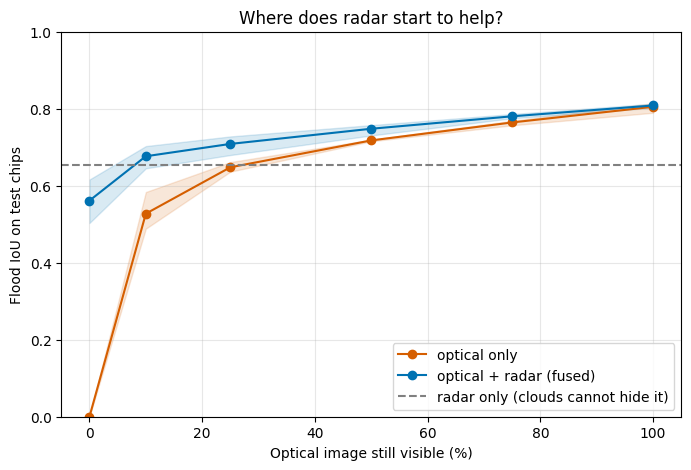

 visible %  optical only    fused  radar gain
       100         0.805    0.808      +0.003
        75         0.764    0.780      +0.016
        50         0.718    0.748      +0.030
        25         0.648    0.709      +0.061
        10         0.527    0.677      +0.149
         0         0.000    0.561      +0.561


In [25]:
cl = collections.defaultdict(lambda: collections.defaultdict(list))   # cl[mode][level] = list of IoU (one per seed)
with open(CLOUD_FILE) as f:                              # read the results file
    for row in csv.reader(f):                            # line by line
        if len(row) == 4:                                # complete lines only
            cl[row[0]][float(row[2])].append(float(row[3]))   # store IoU under mode and level

radar = [v for v in runs["s1"].values()] if "runs" in globals() and runs.get("s1") else []   # radar-only scores from Part 7 (flat line)
levels = sorted(TEST_LEVELS)                             # 0.0 ... 1.0
names = {"s2": "optical only", "both": "optical + radar (fused)"}   # legend text
colors = {"s2": "#D55E00", "both": "#0072B2"}            # colour-blind-safe orange and blue
plt.figure(figsize=(8, 5))                               # canvas
for m in CLOUD_MODES:                                    # one line per model
    mean = [st.mean(cl[m][a]) for a in levels]          # mean over seeds
    lo = [min(cl[m][a]) for a in levels]                # worst seed
    hi = [max(cl[m][a]) for a in levels]                # best seed
    plt.plot([a * 100 for a in levels], mean, "o-", color=colors[m], label=names[m])   # the line
    plt.fill_between([a * 100 for a in levels], lo, hi, color=colors[m], alpha=0.15)   # band = spread across seeds
if radar:                                                # if radar-only results exist
    plt.axhline(st.mean(radar), color="grey", ls="--", label="radar only (clouds cannot hide it)")   # floor line
plt.xlabel("Optical image still visible (%)")            # x label
plt.ylabel("Flood IoU on test chips")                    # y label
plt.title("Where does radar start to help?")             # title
plt.ylim(0, 1); plt.grid(alpha=0.3); plt.legend(loc="lower right")   # axis limit, grid, legend
plt.savefig("cloud_experiment.png", dpi=150, bbox_inches="tight")   # save the picture
plt.show()                                               # show it

print(f"{'visible %':>10}{'optical only':>14}{'fused':>9}{'radar gain':>12}")   # table heading
for a in reversed(levels):                               # from clear to fully clouded
    o, b = st.mean(cl["s2"][a]), st.mean(cl["both"][a]) # the two means
    print(f"{a*100:>10.0f}{o:>14.3f}{b:>9.3f}{b - o:>+12.3f}")   # gain = fused minus optical-only
